##  LECTURE7 : Data Augmentation

- 1교시: Torch transfoorm, albumentation
- 2교시: Augmentation 선택과 Auto Augment
- 3교시: Batch Normalization, Dropout
- 4교시: Regularization
- 5교시: Ensemble model


# [1교시] Data augmentation

## What is Data Augmentation?
- Image Augmentation이란 하나의 원본 이미지에 약간의 변형을 더해 여러 새로운 Training Sample을 만들어내는 것을 의미합니다.

![이미지](https://albumentations.ai/docs/images/introduction/image_augmentation/augmentation.jpg)

출처 : https://albumentations.ai/docs/introduction/image_augmentation/






## Why Data Augmentation?

>Deep Learning은 좋은 성능을 내고, 오버피팅을 막기 위해서 굉장히 많은 양의 데이터를 요구하고 있습니다.

>하지만 아래와 같은 이유로 데이터수집에 어려움을 겪는 경우가 종종, 아니 생각보다 많이 있습니다.

### labeling 과정에서 소모되는 돈, 시간
> 만약 Object Detection을 위한 데이터를 수집한다면, 여러분은 원하는 Object에 Box를 그려주어야 할 것입니다. 심지어 Classification까지 추가된다면, Box뿐만 아니라, 해당 object가 속한 class도 사람이 직접 데이터셋에 표현해 주어야 합니다. 만약 데이터셋이 Medical과 같은 전문 분야의 데이터라면, 비싼 인력을 고용하여 labeling을 해야 할 것입니다.

### 데이터 수집의 어려움
> Health care분야의 데이터의 경우 법적으로 규제가 심해서 데이터를 구하기 쉽지 않습니다.

> 위성영상의 경우 원하는 사진을 찍기 위해 위성을 보내야하는 기회비용이 존재합니다.

> 도로사진의 경우, 직접 차를 운전하여 방방곳곳을 돌아다녀야 한다는 기회비용이 존재합니다.

##How Data Augmentation affects for Learning

- No augmentations 보다 augmentation이 추가된 것이 더 좋은 performance를 보였다.
 - 괄호 안에 test acc 참고

![image](https://sebastianraschka.com/images/blog/2023/data-augmentation-pytorch/augmentation-results.png)

출처 : https://sebastianraschka.com/blog/2023/data-augmentation-pytorch.htm



> **Start Augmentation!**





In [ ]:
%matplotlib inline

## Augmentation with Pytorch

### 라이브러리 가져오기

>https://pytorch.org/vision/stable/transforms.html


In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

### MNIST데이터셋 가져오기 + Augmentation

In [ ]:
# 데이터 로드 및 Augmentation 설정
torchvision_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomCrop(24),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

torch_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=torchvision_transform, download=True)
torch_dataloader = torch.utils.data.DataLoader(torch_dataset, batch_size=4, shuffle=True)

100%|██████████| 9912422/9912422 [00:00<00:00, 115688291.81it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw



100%|██████████| 28881/28881 [00:00<00:00, 52736479.68it/s]

Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw




100%|██████████| 1648877/1648877 [00:00<00:00, 39311589.58it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw



100%|██████████| 4542/4542 [00:00<00:00, 11524820.79it/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



###클래스 레이블 정의

In [ ]:
# 클래스 레이블 정의
classes = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')

### Data Loader 에서 첫 배치 가져오기

In [ ]:
# 데이터셋에서 이미지를 무작위로 가져와서 시각화
data_iter = iter(torch_dataloader)
images, labels = next(data_iter)

###이미지 출력

9     3     2     1    


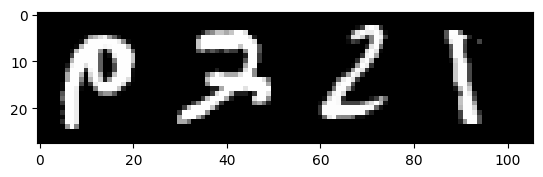

In [ ]:
# 이미지 출력
plt.imshow(torchvision.utils.make_grid(images).permute(1,2,0))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

###Pytorch 공식 홈페이지에서 모듈 가져와 사용하기
> Pytorch 공식 홈페이지 : https://pytorch.org/vision/stable/transforms.html

위 사이트에서 Pytorch가 갖고있는 augmentation method를 확인할 수 있다.

더 자세한 내용은 모듈 이름을 클릭하여 제일 아래에 Example using으로 들어가면 예제까지 볼 수 있다.

In [ ]:
#example to use albumentation
"""
만약 위 홈페이지에서 ColorJitter 라는 augmentation method를 선택했다면?
"""
transform = transforms.Compose(
    transforms.ColorJitter(brightness=.5, hue=.3) # 이외에 홈페이지에 있는 파라미터도 사용하면 된다
)


# -----------------------아래쪽은 앞서 실습한 것과 동일합니다.--------------------------#
albumentation_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)
albumentation_dataloader = torch.utils.data.DataLoader(albumentation_dataset, batch_size=4, shuffle=True)

##Augmentation with Albumentation

###라이브러리 가져오기

In [1]:
from PIL import Image
import cv2
import numpy as np
import time
import torch
import torchvision
from torch.utils.data import Dataset
from torchvision import transforms
import albumentations as A
from albumentations.pytorch import ToTensorV2
from matplotlib import pyplot as plt

###MNIST데이터셋 가져오기 + Augmentation

In [2]:
A_transform = A.Compose([
    A.Resize(28, 28),
    A.RandomCrop(24,24),
    A.HorizontalFlip(), # Same with transforms.RandomHorizontalFlip()
    ToTensorV2()
])

class Transforms:

    """
    Data Loader가 데이터를 불러올 때 augmentation이 같이 호출되어 augmented된 형태로 이미지가 불려나가게 된다.
    이 때, Albumentation은 augmentation을 하고자 이미지를 transform의 parameter로 넣어줄 때
    image = image의 형태로 넣어주어야 하는데, torchvision dataset에서는 해당 기능을 제공하지 않기 때문에
    torchvision dataset에 transform을 넣어주기 전에 클래스를 따로 생성해서 해당기능을 포함한 채로
    transform에 넣어주어야 한다.

    클래스를 만들어주지 않고 바로 torchvision dataset을 사용했을 경우에 발생하는 에러는 아래와 같다
    KeyError: 'You have to pass data to augmentations as named arguments, for example: aug(image=image)'

    궁금하면 이 클래스를 주석처리하고, 아래 torchvision.datasets.MNIST( ... , transform=A_transform, ...)으로 변경 후
    아래에 "Dataloader에서 첫 배치 가져오기" 셀 실행해보기
    """

    def __init__(self, transforms: A.Compose):
        self.transforms = transforms

    def __call__(self, img, *args, **kwargs):
        return self.transforms(image=np.array(img))

transform = Transforms(transforms = A_transform)

albumentation_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                                                   transform=transform, download=True)
albumentation_dataloader = torch.utils.data.DataLoader(albumentation_dataset, batch_size=4, shuffle=True)

100%|██████████| 9912422/9912422 [00:00<00:00, 90257190.59it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw



100%|██████████| 28881/28881 [00:00<00:00, 17474854.85it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw



100%|██████████| 1648877/1648877 [00:00<00:00, 31484097.90it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw



100%|██████████| 4542/4542 [00:00<00:00, 20797520.49it/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



###클래스 레이블 정의

In [ ]:
# 클래스 레이블 정의
classes = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')

### Data Loader 에서 첫 배치 가져오기

In [ ]:
# 데이터셋에서 이미지를 무작위로 가져와서 시각화
data_iter = iter(albumentation_dataloader)
images, labels = next(data_iter)

###이미지 출력

2     3     2     9    


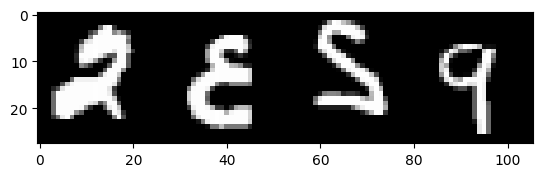

In [ ]:
# 이미지 출력
plt.imshow(torchvision.utils.make_grid(images["image"]).permute(1,2,0))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

###Albumentation 공식 홈페이지에서 모듈 가져와 사용하기
> albumentation 공식 홈페이지 : https://demo.albumentations.ai/

위 사이트에서 albumentaion이 갖고있는 augmentation method를 확인할 수 있다.

***사용법***
- 사이트에 Select a transform으로 선택하게 되어있는것이 모듈 이름이다.
- 사이트에 모듈 이름 아래에 Params of ~ 아래에 있는 parameter들이 실제로 모듈의 parameter이다.

In [ ]:
#example to use albumentation
"""
만약 위 홈페이지에서 AdvancedBlur 라는 augmentation method를 선택했다면?
"""
#import Albumentation as A
transform = A.Compose(
    A.AdvancedBlur(blur_limit = 37, sigmaX_limit=0.5) # 이외에 홈페이지에 있는 파라미터도 사용하면 된다
)


# -----------------------아래쪽은 앞서 실습한 것과 동일합니다.--------------------------#
class Transforms:
    def __init__(self, transforms: A.Compose):
        self.transforms = transforms

    def __call__(self, img, *args, **kwargs):
        return self.transforms(image=np.array(img))


transform = Transforms(transforms = transform)


albumentation_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform,
                                                   download=True)
albumentation_dataloader = torch.utils.data.DataLoader(albumentation_dataset, batch_size=4, shuffle=True)

/usr/local/lib/python3.10/dist-packages/albumentations/core/composition.py:53: UserWarning: transforms is single transform, but a sequence is expected! Transform will be wrapped into list.
  warnings.warn(


## Torch vs Albumentation
- torch로 transform을 선언하는 것 보다 albumentation으로 transform을 구성하는게 시간이 훨씬 단축된다

In [ ]:
import time

# 데이터 로드 및 Augmentation 설정
torchvision_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomCrop(24),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

torch_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=torchvision_transform, download=True)
torch_dataloader = torch.utils.data.DataLoader(torch_dataset, batch_size=4, shuffle=True)


"""--------------------아래에서 부터는 시간 측정하는 부분 ---------------------------"""
torch_start = time.time()

for images, labels in torch_dataloader:
    pass

torch_end = time.time()
print(f"torch_dataload_time = {torch_end - torch_start:.4f} sec")

torch_dataload_time = 18.8505 sec


In [7]:
import time
A_transform = A.Compose([
    A.Resize(28, 28),
    A.RandomCrop(24,24),
    A.HorizontalFlip(), # Same with transforms.RandomHorizontalFlip()
    ToTensorV2()
])

class Transforms:

    def __init__(self, transforms: A.Compose):
        self.transforms = transforms

    def __call__(self, img, *args, **kwargs):
        return self.transforms(image=np.array(img))

transform = Transforms(transforms = A_transform)

albumentation_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)
albumentation_dataloader = torch.utils.data.DataLoader(albumentation_dataset, batch_size=4, shuffle=True)



"""--------------------아래에서 부터는 시간 측정하는 부분 ---------------------------"""
albumentation_start = time.time()

for images, labels in albumentation_dataloader:
    pass

albumentation_end = time.time()
print(f"albumentation_dataload_time = {albumentation_end-albumentation_start:.4f} sec")


albumentation_dataload_time = 8.8513 sec


In [5]:
%%time
for images, labels in albumentation_dataloader:
    pass

CPU times: user 8.78 s, sys: 44.5 ms, total: 8.82 s
Wall time: 8.87 s


# [2교시] Augmentation 선택과 Auto Augment

## 좋은 Augmentation Method를 선택하는 방법
> Augmentation은 데이터의 유효한 정보를 잘 보존하며 다양성을 많이 증가시키는 방법이 좋다.

> **example 1**
![image](https://blog.kakaocdn.net/dn/b7fmua/btqWVSMBevN/BzTdTP90jwXk00i2sEtZ81/img.png)
- 고양이는 돌리던 뒤집던 어떻게 회전시키던 고양이다

> **example2**

![image](https://www.researchgate.net/publication/346701220/figure/fig2/AS:966307725996033@1607397123511/Examples-of-data-augmentation-transformations-on-an-image-from-the-MNIST-dataset-a.jpg)
- 5는 vertical flip되면 2와 구분하기 힘들어지고, 6은 vertical flip + horizontal flip되면 9와 구분할 수 없어진다. **Augmentation으로 자신의 정보를 잃게 되는 것이다.**

## 각자 원하는 augmentation method를 골라잡아 MNIST dataset 분류기의 성능을 향상시켜보자!

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import albumentations as A
from albumentations.pytorch import ToTensorV2
import time

###Pytorch Augmentation, Data Loader

In [ ]:
"""--------------------------------Pytorch-----------------------------------"""

# Define the transforms to preprocess the data
#pytorch augment 모듈 모음 : https://pytorch.org/vision/stable/transforms.html
transform = transforms.Compose([
     #transforms.RandomAffine(20),
     #transforms.Resize((28,28)),
     #transforms.CenterCrop((28,28)),
     #transforms.Normalize((0.5,), (0.5,))
     transforms.ToTensor(),
    ])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

# Define data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

method = "Pytorch"

### Albumentation Augmentation, Dataloader

In [ ]:
"""------------------------------ Albumentations-----------------------------"""
#Albumentation 모듈 모음 : https://demo.albumentations.ai/
A_transform = A.Compose([
    #A.Resize(28, 28),
    #A.RandomCrop(24,24),
    #A.HorizontalFlip(),
    #A.Normalize((0.5,), (0.5,))
    ToTensorV2()
])

class Transforms:

    def __init__(self, transforms: A.Compose):
        self.transforms = transforms

    def __call__(self, img, *args, **kwargs):
        return self.transforms(image=np.array(img))

transform = Transforms(transforms = A_transform)

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

# Define data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

method = "Albumentations"

### Train, Test Loop
augmentation을 추가했으니 train loss가 떨어지는 속도가 조금 느릴 수 있습니다!

In [ ]:
#--------------아래에서 부터는 모델에 손대는 것, 저희는 Augmentation만 바꿔봅시다-----------#
#Select Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("your device = ", device)
# Define a simple feedforward neural network model
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)  # Flatten the input
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x

# Initialize the model, loss function, and optimizer
net = Net()
net.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

net.train()
# Training loop
for epoch in range(10):  # You can adjust the number of epochs
    running_loss = 0.0
    start_time = time.time()
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data

        if type(inputs) == dict:
          inputs = inputs["image"].to(dtype = torch.float32)
        """
        albumentation이 augmentation 하는 경우 torch와 데이터타입이 맞지 않아서 맞춰주는 부분
        label은 augment 과정이 없기때문에 albumentations가 손대지 않아서
        torch와 데이터타입이 동일함
        """

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item()
    print(f"[Epoch {epoch}] Loss: {running_loss / len(train_loader):.4f}, \
    {method}_time = {time.time()-start_time:.4f} sec")

print("Finished Training")

# Evaluation
correct = 0
total = 0
net.eval()
with torch.no_grad():
    for data in test_loader:
        inputs, labels = data

        if type(inputs) == dict:
          inputs = inputs["image"].to(dtype = torch.float32)

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = net(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy on test data: {100 * correct / total}%")

your device =  cpu
[Epoch 0] Loss: 0.3307,     Albumentations_time = 9.5390 sec
[Epoch 1] Loss: 0.1423,     Albumentations_time = 10.5240 sec
[Epoch 2] Loss: 0.1127,     Albumentations_time = 9.2255 sec
[Epoch 3] Loss: 0.0981,     Albumentations_time = 10.0245 sec
[Epoch 4] Loss: 0.0894,     Albumentations_time = 10.1004 sec
[Epoch 5] Loss: 0.0834,     Albumentations_time = 10.9973 sec
[Epoch 6] Loss: 0.0740,     Albumentations_time = 13.6237 sec
[Epoch 7] Loss: 0.0722,     Albumentations_time = 13.2583 sec
[Epoch 8] Loss: 0.0654,     Albumentations_time = 10.2626 sec
[Epoch 9] Loss: 0.0644,     Albumentations_time = 10.2744 sec
Finished Training
Accuracy on test data: 96.4%


### 실습 결론
- 네트워크를 잘 구성하는 것도 중요하지만, 그 전에 데이터를 열어보고, 분석하여 해당 데이터셋에 맞는 학습을 구성하는것도 굉장히 중요하다!

*참고

data augmentation을 추가해줄 경우에 augmentation이 없는 학습보다 학습속도 자체는 느릴 수 있습니다. 하지만 epoch을 늘려 많은 학습을 진행할 경우, augmentation이 없는 학습보다 더 좋은 성능을 보여줍니다.

## Google의 Auto Augment
데이터를 학습시키는 과정에서, 그 정확도를 보고 강화학습으로 적절한 Augment Method를 골라주는 강화학습 모델을 Google이 개발

pytorch Auto Augment 공식홈페이지 : https://pytorch.org/vision/stable/generated/torchvision.transforms.AutoAugment.html?highlight=auto+augment#torchvision.transforms.AutoAugment


- 의의
> 이 방법이 나오기 전까지는 데이터셋을 사람이 보고, 직관적으로 augmentation을 선택했다. 하지만 이를 강화학습으로 대체하여 효율적으로 augmentor를 선택할 수 있게 하였고, 성능적 향상도 이루어 내었다. (이전 사람의 직관으로 선택된 augmentation 기법보다 확실한 강세를 보였음)
> Best Policy의 선정을 위해서는 80~120epoch 정도의 학습이 필요하다고 한다.

출처 : https://deepkerry.tistory.com/27

In [ ]:
"""
policy : 강화학습에서, 모델이 현재 상황을 고려하여 선택하는 어떤 행동(정책)
어떤 데이터셋으로 학습시켰는지에 따라 policy가 다르게 결정된다.
ex) CIFAR10의 경우 color-based policy,
    SVHN의 경우 rotate, equalize가 강하게 결정되었다.

[policy 종류]
transforms.AutoAugmentPolicy.IMAGENET (default)
transforms.AutoAugmentPolicy.CIFAR10
transforms.AutoAugmentPolicy.SVHN
"""

#아래와 같이 transforms.Compose에 AutoAugment만 추가해주면 바로 사용가능하다.
transform = transforms.Compose([
      transforms.AutoAugment(policy = transforms.AutoAugmentPolicy.IMAGENET),
      transforms.ToTensor()
    ])


###pytorch transform에 Auto Augment 추가

In [ ]:
"""--------------------------------Pytorch-----------------------------------"""

# Define the transforms to preprocess the data
#pytorch augment 모듈 모음 : https://pytorch.org/vision/stable/transforms.html
train_transform = transforms.Compose([
     #transforms.RandomAffine(20),
     #transforms.Resize((28,28)),
     #transforms.CenterCrop((28,28)),
     #transforms.Normalize((0.5,), (0.5,))
     transforms.AutoAugment(policy = transforms.AutoAugmentPolicy.SVHN),
     transforms.ToTensor(),
    ])
test_transform = transforms.Compose([
     #transforms.RandomAffine(20),
     #transforms.Resize((28,28)),
     #transforms.CenterCrop((28,28)),
     #transforms.Normalize((0.5,), (0.5,))
     transforms.ToTensor(),
    ])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, transform=train_transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=test_transform, download=True)

# Define data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

method = "Pytorch"

###Train, Test Loop

In [ ]:
#--------------아래에서 부터는 모델에 손대는 것, 저희는 Augmentation만 바꿔봅시다-----------#
#Select Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("your device = ", device)

# Define a simple feedforward neural network model
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)  # Flatten the input
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x

# Initialize the model, loss function, and optimizer
net = Net()
net.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

# Training loop
for epoch in range(10):  # You can adjust the number of epochs
    running_loss = 0.0
    start_time = time.time()
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item()
    print(f"[Epoch {epoch}] Loss: {running_loss / len(train_loader):.4f}, \
    {method}_time = {time.time()-start_time:.4f} sec")

print("Finished Training")

# Evaluation
correct = 0
total = 0
with torch.no_grad():
    for data in test_loader:
        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = net(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy on test data: {100 * correct / total}%")

your device =  cpu
[Epoch 0] Loss: 1.0889,     Pytorch_time = 35.1237 sec
[Epoch 1] Loss: 0.5892,     Pytorch_time = 35.5054 sec
[Epoch 2] Loss: 0.4588,     Pytorch_time = 36.2170 sec
[Epoch 3] Loss: 0.4008,     Pytorch_time = 36.2583 sec
[Epoch 4] Loss: 0.3630,     Pytorch_time = 35.8767 sec
[Epoch 5] Loss: 0.3395,     Pytorch_time = 35.3934 sec
[Epoch 6] Loss: 0.3204,     Pytorch_time = 35.2470 sec
[Epoch 7] Loss: 0.3014,     Pytorch_time = 59.0931 sec
[Epoch 8] Loss: 0.2857,     Pytorch_time = 38.7196 sec
[Epoch 9] Loss: 0.2790,     Pytorch_time = 35.4225 sec
Finished Training
Accuracy on test data: 97.3%


###실험 결과
Non Augmentation vs Auto Augmentation

> accuracy : 96.75% vs **97.71**%


![](https://pytorch.org/vision/stable/_images/sphx_glr_plot_transforms_020.png)

## Test Time Augmentation (TTA)
![image](https://user-images.githubusercontent.com/31475037/123568577-94eb1a00-d7ff-11eb-8182-14abc59ce384.png)

> TTA의 예시는 다음과 같습니다. 원본 입력 이미지 한 장을 augmentation해 2장을 생성해냅니다. 총 3장의 이미지를 학습된 모델에 각각 입력해주고, 모델에서 나온 예측 확률 값(score)을 평균해 최종 클래스를 예측합니다.

In [ ]:
"""--------------------------------Pytorch-----------------------------------"""

# Define the transforms to preprocess the data
#pytorch augment 모듈 모음 : https://pytorch.org/vision/stable/transforms.html
train_transform = transforms.Compose([
     #transforms.RandomAffine(20),
     #transforms.Resize((28,28)),
     #transforms.CenterCrop((28,28)),
     #transforms.Normalize((0.5,), (0.5,))
     #transforms.AutoAugment(policy = transforms.AutoAugmentPolicy.SVHN),
     transforms.ToTensor(),
    ])
test_transform = transforms.Compose([
     #transforms.RandomAffine(20),
     #transforms.Resize((28,28)),
     #transforms.CenterCrop((28,28)),
     #transforms.Normalize((0.5,), (0.5,))
     transforms.ToTensor(),
    ])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, transform=train_transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=test_transform, download=True)

# Define data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

method = "Pytorch"

In [ ]:
!pip install ttach
import ttach as tta

# defined 2 * 2 * 3 * 3 = 36 augmentations !
transforms = [tta.HorizontalFlip(),
        tta.Rotate90(angles=[0, 180]),
        tta.Scale(scales=[1, 2, 4]),
        tta.Multiply(factors=[0.9, 1, 1.1])]
"""이걸로 모델 감싸서 model 대신 tta_model 사용하면 됩니다."""
# tta_model = tta.ClassificationTTAWrapper(model, transforms, merge_mode = "mean") #merge_mode = 'mean', 'gmean', 'sum', 'max', 'min', 'tsharpen'


'이걸로 모델 감싸서 model 대신 tta_model 사용하면 됩니다.'

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import albumentations as A
from albumentations.pytorch import ToTensorV2
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("your device = ", device)

# Define a simple feedforward neural network model
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)  # Flatten the input
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x

# Initialize the model, loss function, and optimizer
net = Net()
net.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

# Training loop
for epoch in range(10):  # You can adjust the number of epochs
    running_loss = 0.0
    start_time = time.time()
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item()
    print(f"[Epoch {epoch}] Loss: {running_loss / len(train_loader):.4f}, \
    {method}_time = {time.time()-start_time:.4f} sec")

print("Finished Training")

transforms = tta.Compose(
    [
        tta.HorizontalFlip(),
        tta.Rotate90(angles=[0, 180]),
        tta.Multiply(factors=[0.9, 1, 1.1])
        ])

tta_model = tta.ClassificationTTAWrapper(net, transforms, merge_mode = "mean") #merge_mode = 'mean', 'gmean', 'sum', 'max', 'min', 'tsharpen'
print(tta_model.transforms)

# Evaluation
correct = 0
total = 0
net.eval()
with torch.no_grad():
    for data in test_loader:
        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = tta_model(inputs) #여기서 tta model 사용!!
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy on test data: {100 * correct / total}%")

your device =  cpu
[Epoch 0] Loss: 0.3306,     Pytorch_time = 15.1337 sec
Finished Training
Accuracy on test data: 58.04%


#[3교시] Batch Normalization, Dropout

##Covariate Shift
![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbrz8Im%2Fbtq4CijbLUR%2FBaeMc4KJijoX1CdxqjKUr1%2Fimg.png)

출처 : https://cvml.tistory.com/m/5

- 고양이와 강아지를 분류하는 모델을 학습시킬 때 학습 데이터로 고양이 이미지를 '러시안 블루'종만 사용하고 테스트 데이터로 '페르시안'종의 고양이를 분류하려고 한다면 모델은 잘 학습할 수 있을까? 학습 데이터의 분포와 테스트 데이터의 분포가 다르기 때문에 학습시킨 모델의 분류 성능은 떨어질 것이며 이처럼 학습 데이터와 테스트 데이터의 분포가 다른 것을 covariate shift라 부른다.


##Internal Covariate Shift
- 딥러닝에서는 위의 Covariate Shift가 Layer 마다 일어난다. Layer를 통과할 때 마다 input의 분포에 변형이 일어나고, Layer를 지남에 따라 변형이 심해져 학습에 나쁜 영향을 주게되는 것이다.

- 또한, 계층의 parameter가 업데이트 되면, 다음 계층은 당연히 업데이트 전후로 다른 분포의 input을 받게되어 covariate shift가 발생한다.

![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcyscr7%2Fbtq4AtZz7ST%2FOXf1ywXwrkCaNhT8bQCaO1%2Fimg.png)

출처 : https://cvml.tistory.com/m/5

##Whitening

![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcpCNWE%2Fbtq4HZWzSfK%2FhLFtMWpqfo0xclWf20dNo0%2Fimg.png)

출처 : https://cvml.tistory.com/m/5

- 위의 covariate shift를 해결하기 위해 고안된 방법이다. 간단히 말해서, 평균이 0, 표준편차가 1로 데이터의 분포를 변환해주는 것이다.

 - 그러나, Whitening은 parameter를 업데이트 하는 연산과 상쇄되어 실제로 특정 parameter가 전혀 Optimize 되지 않는 모습을 보였다.
 - [논문에서의 예시]
 - $\hat{x} = x - \mathbb{E}[x] \quad \text{where, } \mathbb{E}[x] = \frac{1}{N} \sum_{i=1}^{N} x_i$

 - $u + (b + \Delta b) - \mathbb{E}[u + (b + \Delta b)] = u + b - \mathbb{E}[u + b]$

  - 결국 $\Delta b$로 b를 업데이트 했지만, 분포가 바뀌며 해당 Optimize가 무시되었다.

##Batch Normalization
![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FENgn2%2Fbtq4F27Avlg%2F0lGC2vYOp4lHIrW1SUFDo0%2Fimg.png)

출처 : https://cvml.tistory.com/m/5

$$\mu_{B}\leftarrow\frac{1}{m}\sum_{i=1}^{m}x_{i}$$

$$\sigma^{2}_{B}\leftarrow\frac{1}{m}\sum_{i=1}^{m}\left( x_{i}-\mu_{B} \right)^{2}$$

- 입력 데이터에 대하여 각 차원(feature)별로 normalization을 수행
- epsilon이 붙는 이유는 0으로 나눠지는 것을 막기 위해

$$\hat{x}_{i}\leftarrow\frac{x_{i}-\mu_{B}}{\sqrt{\sigma^{2}_{B}+\epsilon}}$$

- normalization 된 값들에 대해 Scale factor(gamma)와 Shift factor(beta)를 더하여 학습이 가능한 파라미터를 추가함

$$y_{i}\leftarrow\gamma\hat{x}_{i}+\beta\equiv BN_{\gamma,\beta}\left(x_{i}\right)$$

- $\gamma, \beta$는 학습가능한 parameter이다.

**Scale factor**의 존재 이유

![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FlDXk8%2FbtrKoS5zWel%2FwnZUe8Qa8cdPLvnMyMz2k0%2Fimg.png)

출처 : https://killerwhale0917.tistory.com/13

> normalize를 진행하게되면, 이후 만날 sigmoid function에서 0 부근에 데이터가 집중된다. 해당 부분은 거의 Linear하여 비선형성이 부족함으로 인해 학습이 잘 진행되지 않으므로,Normalize된 input에 Scaling과 Shifting을 해준다.

##Inference with Batch Normalization
그러면 이제 학습이 완료되고 난 다음에 추론 과정에서 Batch Normalization layer는 어떻게 정규화를 수행할까?

추론 과정에서는 테스트 데이터 하나에 대해 답을 내야 하므로 평균과 분산을 계산할 수 없다.

따라서 추론할 때는 training set의 평균과 분산 값으로 대체하여 정규화를 수행한다. 대체하는 방법으로는 크게 2가지가 있으며 학습할 때 사용했던 mini batch의 평균과 분산 값들을 이용한다.

***모집단 추정방식***
- 표본평균을 모아 평균을 내면 모집단의 평균을 추정할 수 있다는 방식
$$E \left [ x^{\left(k\right)}\right] = E_{B}\left[\mu^{\left(k\right)}_{B}\right]$$

$$Var\left[x^{\left(k\right)}\right] = \frac{m}{m-1}E_{B}\left[\sigma^{\left(k\right)^{2}}_{B}\right]$$

***Moving Average 방식***
- 평균과 표준편차에 대해서 현재 batch와 직전까지의 batch 사이를 $(\alpha, 1-\alpha)$로 내분하는 내분점을 반복해서 찾아나감

$$\hat{\mu}\leftarrow\alpha\hat{\mu}+\left(1-\alpha\right)\mu^{\left(i\right)}_{B}$$

$$\hat{\sigma}\leftarrow\alpha\hat{\sigma}+\left(1-\alpha\right)\sigma^{\left(i\right)}_{B}$$

모든 배치에 대한 평균을 저장하고있어야 하는 모집단 추정방식보다 Moving Average방식을 많이 지향한다고 한다.

###Batch Normalization에 대한 TMI
- Trainable Parameter가 있어 layer로 인정받는다.
- 보통 activation 직전에 들어간다. (Scaling, Shift의 존재이유)
- Convolution, Batch Normalization, Dropout, activation이 자주 묶여서 사용된다.


논문 출처 : Ioffe, Sergey, and Christian Szegedy. "Batch normalization: Accelerating deep network training by reducing internal covariate shift." International conference on machine learning. pmlr, 2015.

https://arxiv.org/pdf/1502.03167.pdf


## Dropout의 개념
![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fm5YtD%2FbtrbwgszFXZ%2FxdUhkeyK2lmrQXYy7HioL0%2Fimg.png)

- Drop-out은 서로 연결된 연결망(layer)에서 0부터 1 사이의 확률로 뉴런을 제거(drop)하는 기법

- 위의 그림은 drop-out rate가 0.5라서 50%의 뉴런이 비활성화됨

- 노드가 데이터셋에 대해 과하게 fit되는것을 막음으로써 **overfitting**을 어느정도 해소할 수 있다.


##실습해보기 !

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader



"""-----------------------------아래쪽을 바꿔보세요-------------------------------"""
# Define the transforms for data preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
"""--------------------------------------------------------------------------"""


# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

# Define data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)



"""----------------------------아래쪽을 바꿔보세요----------------------------------"""
# Define a CNN model with Batch Normalization
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(1,32,3),
                                    nn.Dropout2d(0.25),
                                    nn.BatchNorm2d(32),
                                    nn.ReLU(),
                                    nn.MaxPool2d(2)
                                    )

        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3),
                                    nn.BatchNorm2d(64),
                                    nn.ReLU(),
                                    nn.MaxPool2d(2))

        self.fc_layer = nn.Sequential(nn.Linear(64*5*5, 128),
                                      nn.BatchNorm1d(128),
                                      nn.ReLU(),
                                      nn.Linear(128,10))


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)

        x = x.view(-1, 64 * 5 * 5)
        x = self.fc_layer(x)

        return x
"""--------------------------------------------------------------------------"""


# Initialize the model, loss function, and optimizer
model = Net()


"""---------------------------아래쪽을 바꿔보세요----------------------------------"""
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
"""--------------------------------------------------------------------------"""

# Training loop
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch + 1}, Loss: {running_loss / len(train_loader)}")


# Evaluation
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on test data: {accuracy:.2f}%")


#[4교시] Regularization

L0 Norm vs L-inf Norm

## L1 Norm
![image](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F1d14f5ea-98f9-4a28-af7a-09efbbedffcf%2Fimage.png)



##L2 Norm
![image](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F63abb1da-5ee3-41e3-a72a-c0f1f0b7486e%2Fimage.png)

##L1, L2 Norm의 시각화

![이미지](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F942e28d3-cc8b-4c09-b752-059044b17e9c%2Fimage.png)
- 초록색 : L2 Norm (Euclidean distance)
- 그 외 : L1 Norm (taxi distance)

## L1 Regularization
![iamge](https://velog.velcdn.com/images%2Fdongho5041%2Fpost%2F451c0978-2d71-49ed-8d73-4352d2332308%2Fimage.png)

- $\lambda |w|$ : 패널티 (w에 따라 loss를 증가시킨다)

##L2 Regularization
![image](https://velog.velcdn.com/images%2Fdongho5041%2Fpost%2Ff9004c22-7358-4458-b86c-ec67972cdaa7%2Fimage.png)

- $\lambda |w|^2$ : 패널티 ($|w|^2$에 따라 loss를 증가시킨다)
- 오류 수정 -> $|w|^2$가 아니라 $w^2$입니다.

## Regularize 의의

![image](https://user-images.githubusercontent.com/45377884/90508764-3c84ce00-e193-11ea-8350-9307399adaa4.png)

- Loss Function에 패널티 요소(Regularization Term)을 더해 기존 Loss에 가중치의 절대값만큼의 패널티를 줌으로써 어느정도의 Loss는 유지하도록 한다.

- 이는 Overfitting을 방지하는 효과가 있다. (실제로 Optimal한 경우가 Overfit된 경우보다 Train Set에서의 Loss가 더 크다)

##L1과 L2의 차이

![이미지](https://media.licdn.com/dms/image/C4D12AQEgtRRdCc0GTQ/article-cover_image-shrink_720_1280/0/1558564556609?e=2147483647&v=beta&t=hxxx8Wa7LxfymOSaMylruyqLPTnUjMSONZyMoj5OWKk)

[그림에 대한 이해]
- $\theta_{1}, \theta_{2}$ 두 개의 parameter로 이루어진 모델을 학습시킨다고 하자.

- 원래는 $\theta_{opt}$로 ($\theta_{1}, \theta_{2}$)가 수렴했어야 했다.

- 하지만, Regularization에 의해 각각 그려져있는 도형 밖으로 나가지 못하고 $\theta_{opt}$와 가장 가까운 도형의 테두리 쪽으로 ($\theta_{1}, \theta_{2}$)가 수렴하게 되었다.

- $\lambda$ 값이 커질수록 Regularization 영역의 크기는 작아질 것이다. (더 강한 규제)

- 위 그림을 통해서 Regularization은 ($\theta_{1}, \theta_{2}$)의 bias를 어느정도 포기하고, variance를 줄여 overfitting을 막는 효과가 있음을 알 수 있다.
(특정 parameter만 커져서 task에 대해 overfit되는 상황 방지)

- 쉽게 말해서, $\theta_{opt}$로 완전히 박혀버리면 Train dataset에 대해 overfit 되어버리기 때문에,(위의 그래프 참고) 적당히 general한 feature만 학습하여 $\theta_{opt}$와 적절한 거리를 유지 할 수 있도록 한다.

[L1, L2의 차이]

- **L1 Regularization**

> 위의 그림에서 Norm의 개념이 필요하다. L1 Norm은 Taxi distance에 의해 $\theta_{opt}$로 부터 거리가 최소인 지점이 여러곳이 나올 수 있다.

> 그림에서는 그 중 $\theta_1$ = 0인 지점을 표현했는데, 이는 L1 Regularization에서 특정 parameter가 0이 될 수 있음을 의미한다. 특정 변수를 삭제할 수 있다는 뜻이다.

- **L2 Regularization**

> 반대로 L2 Norm에서는 $\theta_{opt}$가 축 위에 있는게 아닌 이상 parameter가 0이 되지 않는다.

> 대신 L1 Norm보다 더 general하게 parameter를 학습시킬 수 있다. (L1 Norm보다 $\theta_{opt}$에 더 정교하게 다가갈 수 있다)



## Elastic Net (L1 + L2)

![image](https://static.packt-cdn.com/products/9781838556334/graphics/C12624_04_60.jpg)

- L1과 L2의 패널티를 혼합한 형태

- 단순히 L1 norm과 L2 norm을 혼합한 형태에 불과해보이지만, 이 둘을 동시에 사용함으로써 변수 간 grouping effect를 제공하는 엄청난 이점을 갖게 된다.

- 즉, 변수간 상관관계가 큰 변수들에 유사한 가중치를 줌으로써 중요한 변수들은 똑같이 중요하게 취급하고 중요하지 않은 변수들은 모두 공평하게 중요하지 않게 취급한다.

- 즉, 변수간 상관관계가 커도 중요하지 않은 변수들을 모두 버리면서 중요한 변수들만 잘 골라내어 중요도와 상관관계에 따라 적합한 가중치를 적용할 수 있다.

###Pytorch에서 Regularization 사용하기

Pytorch - Adam 공식 문서 : https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam

- 참고

> pytorch에서 L1 Regularization은 따로 제공되지 않는다고 한다!

> torch.optim.Adam() 의 argument들 중에서, weight_decay가 Regularization의 λ이다. (default : λ = 0)

In [ ]:
torch.optim.Adam(params, lr=0.001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0) #params에 model.parameters()가 들어가야 하는데, 따로 선언한 model이 없다.

##Early Stopping
![image](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F9959E34A5B4C74EA07)

- 말그대로 overfitting이 일어나기 전에 학습을 멈춰버리는 것이다.
- 일반적으로 validation error > train error 가 되는 지점 부근에서 Stopping 한다.

###라이브러리 불러오기

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm


###Network 정의

In [ ]:
# Define a simple convolutional neural network
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5)
        self.fc1 = nn.Linear(1024, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.max_pool2d(x, 2)
        x = torch.relu(self.conv2(x))
        x = torch.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

### Early Stopper 정의

In [ ]:
# Define the early stopping class
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.counter = 1
        self.best_score = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_score is None:
            self.best_score = val_loss
        elif val_loss > self.best_score + self.delta:
            self.counter += 1
            if self.counter > self.patience:
                self.early_stop = True
        else:
            self.best_score = val_loss
            self.counter = 0

### Data Loader 정의

In [ ]:
# Define data transformations and load MNIST dataset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
mnist_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_size = int(0.8 * len(mnist_dataset))
val_size = len(mnist_dataset) - train_size
train_dataset, val_dataset = random_split(mnist_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)


### 클래스 inatnace 선언

In [ ]:
# Initialize the model and optimizer
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Initialize the early stopping object
early_stopping = EarlyStopping(patience=3)

###Loop

In [ ]:
# Training loop with early stopping
num_epochs = 100 #early stopping 때문에 9epoch 정도면 끝납니다.
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch + 1}/{num_epochs}', unit='batch'):
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

    # Calculate average validation loss
    avg_val_loss = val_loss / len(val_loader)

    print(f'Epoch [{epoch + 1}/{num_epochs}] '
          f'Train Loss: {train_loss / len(train_loader):.4f} '
          f'Validation Loss: {avg_val_loss:.4f}')

    # Check for early stopping
    early_stopping(avg_val_loss)
    if early_stopping.early_stop:
        print("Early stopping")
        break




Epoch 1/100: 100%|██████████| 750/750 [01:10<00:00, 10.57batch/s]


Epoch [1/100] Train Loss: 0.1588 Validation Loss: 0.0629


Epoch 2/100: 100%|██████████| 750/750 [01:09<00:00, 10.87batch/s]


Epoch [2/100] Train Loss: 0.0456 Validation Loss: 0.0508


Epoch 3/100: 100%|██████████| 750/750 [01:06<00:00, 11.31batch/s]


...

Epoch [9/100] Train Loss: 0.0096 Validation Loss: 0.0539


Epoch 10/100: 100%|██████████| 750/750 [01:10<00:00, 10.66batch/s]


Epoch [10/100] Train Loss: 0.0079 Validation Loss: 0.0522


Epoch 11/100:  14%|█▎        | 102/750 [00:09<00:58, 11.14batch/s]


KeyboardInterrupt: ignored

##Scikit-learn을 이용한 Regularization 실습

In [1]:
# !pip uninstall scikit-learn -y
# !pip install scikit-learn==1.1

import pandas as pd
import numpy as np
from IPython.display import Image
from sklearn.datasets import load_boston
np.set_printoptions(suppress=True)

ImportError: ignored

데이터 로드

In [ ]:
data = load_boston()

/usr/local/lib/python3.10/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function load_boston is deprecated; `load_boston` is deprecated in 1.0 and will be removed in 1.2.

    The Boston housing prices dataset has an ethical problem. You can refer to
    the documentation of this function for further details.

    The scikit-learn maintainers therefore strongly discourage the use of this
    dataset unless the purpose of the code is to study and educate about
    ethical issues in data science and machine learning.

    In this special case, you can fetch the dataset from the original
    source::

        import pandas as pd
        import numpy as np

        data_url = "http://lib.stat.cmu.edu/datasets/boston"
        raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
        data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
        target = raw_df.values[1::2, 2]

    Alternative datasets include the California housing dataset (i.e.

데이터 프레임 만들기

In [ ]:
df = pd.DataFrame(data['data'], columns = data['feature_names'])
df['MEDV'] = data['target']
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


컬럼 소개 (feature 13 + target 1):

- CRIM: 범죄율

- ZN: 25,000 square feet 당 주거용 토지의 비율

- INDUS: 비소매(non-retail) 비즈니스 면적 비율

- CHAS: 찰스 강 더미 변수 (통로가 하천을 향하면 1; 그렇지 않으면 0)

- NOX: 산화 질소 농도 (천만 분의 1)

- RM:주거 당 평균 객실 수

- AGE: 1940 년 이전에 건축된 자가 소유 점유 비율

- DIS: 5 개의 보스턴 고용 센터까지의 가중 거리

- RAD: 고속도로 접근성 지수

- TAX: 10,000 달러 당 전체 가치 재산 세율

- PTRATIO 도시 별 학생-교사 비율

- B: 1000 (Bk-0.63) ^ 2 여기서 Bk는 도시 별 검정 비율입니다.

- LSTAT: 인구의 낮은 지위

- MEDV: 자가 주택의 중앙값 (1,000 달러 단위)

Training set, Test set 분리

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop('MEDV', 1), df['MEDV'], random_state=23)

<ipython-input-4-811cf4523ab0>:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  x_train, x_test, y_train, y_test = train_test_split(df.drop('MEDV', 1), df['MEDV'], random_state=23)


Scikit-learn 평가지표 활용

In [ ]:
# sklearn 평가지표 활용
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

my_predictions = {}

colors = ['r', 'c', 'm', 'y', 'k', 'khaki', 'teal', 'orchid', 'sandybrown',
          'greenyellow', 'dodgerblue', 'deepskyblue', 'rosybrown', 'firebrick',
          'deeppink', 'crimson', 'salmon', 'darkred', 'olivedrab', 'olive',
          'forestgreen', 'royalblue', 'indigo', 'navy', 'mediumpurple', 'chocolate',
          'gold', 'darkorange', 'seagreen', 'turquoise', 'steelblue', 'slategray',
          'peru', 'midnightblue', 'slateblue', 'dimgray', 'cadetblue', 'tomato'
         ]

# prediction plot
def plot_predictions(name_, actual, pred):
    df = pd.DataFrame({'actual': y_test, 'prediction': pred})
    df = df.sort_values(by='actual').reset_index(drop=True)

    plt.figure(figsize=(12, 9))
    plt.scatter(df.index, df['prediction'], marker='x', color='r')
    plt.scatter(df.index, df['actual'], alpha=0.7, marker='o', color='black')
    plt.title(name_, fontsize=15)
    plt.legend(['prediction', 'actual'], fontsize=12)
    plt.show()

# evaluation plot
def mse_eval(name_, actual, pred):
    global predictions
    global colors

    plot_predictions(name_, actual, pred)

    mse = mean_squared_error(actual, pred)
    my_predictions[name_] = mse

    y_value = sorted(my_predictions.items(), key=lambda x: x[1], reverse=True)

    df = pd.DataFrame(y_value, columns=['model', 'mse'])
    print(df)
    min_ = df['mse'].min() - 10
    max_ = df['mse'].max() + 10

    length = len(df)

    plt.figure(figsize=(10, length))
    ax = plt.subplot()
    ax.set_yticks(np.arange(len(df)))
    ax.set_yticklabels(df['model'], fontsize=15)
    bars = ax.barh(np.arange(len(df)), df['mse'])

    for i, v in enumerate(df['mse']):
        idx = np.random.choice(len(colors))
        bars[i].set_color(colors[idx])
        ax.text(v + 2, i, str(round(v, 3)), color='k', fontsize=15, fontweight='bold')

    plt.title('MSE Error', fontsize=18)
    plt.xlim(min_, max_)

    plt.show()

# remove model
def remove_model(name_):
    global my_predictions
    try:
        del my_predictions[name_]
    except KeyError:
        return False
    return True


# coefficients visulization
def plot_coef(columns, coef):
    coef_df = pd.DataFrame(list(zip(columns, coef)))
    coef_df.columns=['feature', 'coef']
    coef_df = coef_df.sort_values('coef', ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(np.arange(len(coef_df)), coef_df['coef'])
    idx = np.arange(len(coef_df))
    ax.set_yticks(idx)
    ax.set_yticklabels(coef_df['feature'])
    fig.tight_layout()
    plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

###L1 Regularization (lasso)

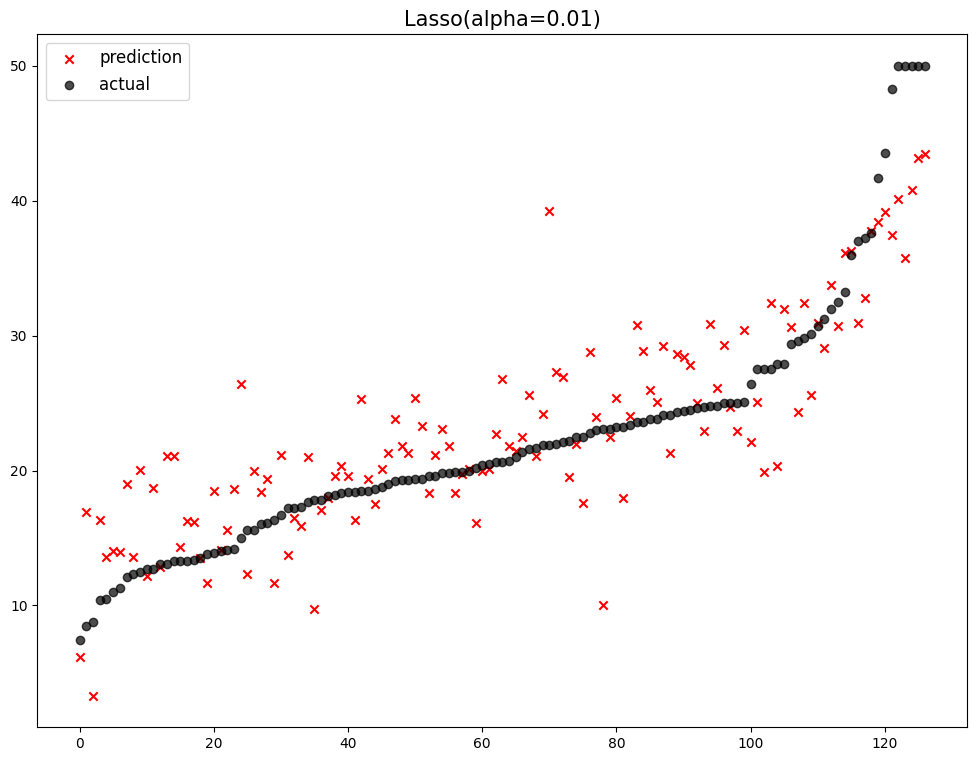

               model        mse
0  Lasso(alpha=0.01)  22.635614


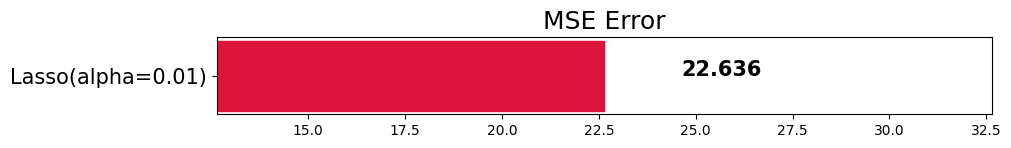

In [ ]:
lasso = Lasso(alpha=0.01)
lasso.fit(x_train, y_train)
lasso_pred = lasso.predict(x_test)
mse_eval('Lasso(alpha=0.01)', lasso_pred, y_test)

### L2 Regularization (Ridge)

In [ ]:
ridge = Ridge(alpha=0.01)
ridge.fit(x_train, y_train) #scikit-learn 내부에서 문제가 있는 것 같아서 계속 오류가 생깁니다. 대신 아래에 MSE error 총 정리한 자료 사진 첨부합니다
ridge_pred = ridge.predict(x_test)
mse_eval('Ridge(alpha=1)', y_test, ridge_pred)

TypeError: ignored

### L1 + L2 (elastic net)

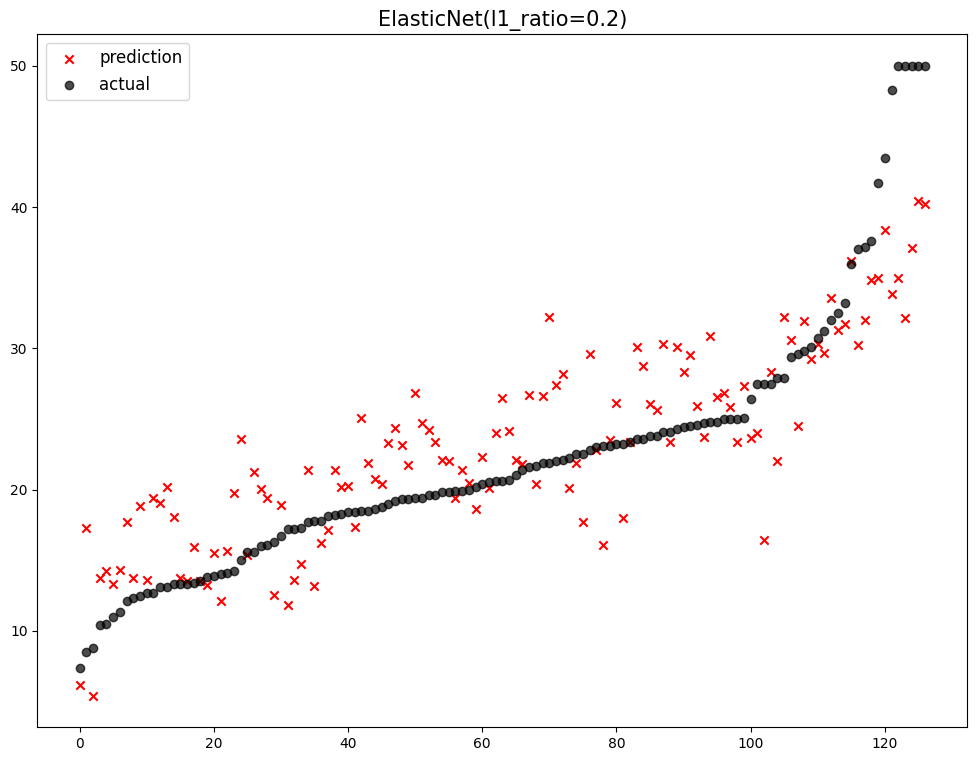

                      model        mse
0  ElasticNet(l1_ratio=0.2)  24.481069
1         Lasso(alpha=0.01)  22.635614


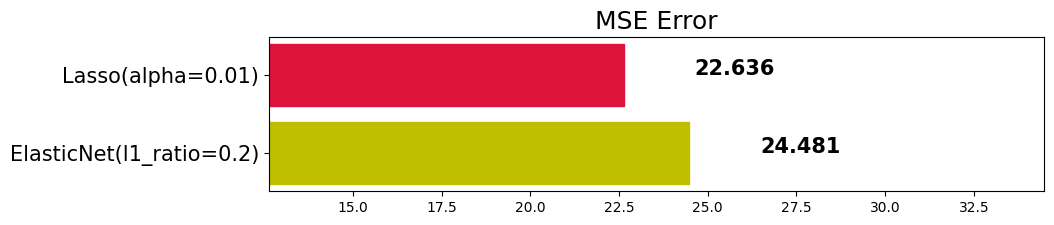

In [ ]:
elasticnet = ElasticNet(alpha=0.5, l1_ratio=0.2)
elasticnet.fit(x_train, y_train)
elas_pred = elasticnet.predict(x_test)
mse_eval('ElasticNet(l1_ratio=0.2)', y_test, elas_pred)

![이미지](https://hyemin-kim.github.io/images/S-Python-sklearn4/output_226_2-1596543997347.png)

##여담 - Multi Task Learning (MTL)

- Soft Parameter Sharing
![image](https://www.ruder.io/content/images/2017/05/mtl_images-002-1.png)

Multi Task Learning의 장점

- Implicit Data Augmentation
> Task A와 Task B를 위한 데이터셋은 서로 다른 noise를 갖고있다. 만약 Task A로만 학습한다면, A의 noise또한 학습되어 overfitting될 수 있다. 여기서 Task B를 함께 학습시켜주면 Share network를 더 general하게 학습이 가능하다.

- 더 다양한 feature를 학습할 수 있다.
> Task A에서 잘 학습되는 어떤 G라는 feature는 Task B를 통해서는 학습이 어려울 수 있다. 이런 경우에 의해 Multi task learning이 효과적으로 feature를 학습시킬 수 있다.
> 예를들어 object detection에서는 location 관련 feature가 잘 학습되고, classification에서는 color 관련 feature가 잘 학습될테니, 두 task를 share network에 통과시켜 학습시키면 share network 는 color와 location에 대한 feature를 잘 학습할 수 있는 것이다.

- 각각의 task가 Regularization 역할을 해준다.
> 위 사진은 Multi Task Learning의 방법 중, Soft Parameter Sharing이다. 각각의 Task를 학습하는 각각의 Network가 각자의 Parameter를 갖는데, 이 때 Network 서로의 Parameter 사이의 distance가 일정 값을 넘지 않도록 비슷하게 유지하는 것이다. 이는 Regularization 역할을 해 주어서 overfitting을 막아준다.

출처 : Ruder, Sebastian. "An overview of multi-task learning in deep neural networks." arXiv preprint arXiv:1706.05098 (2017).

https://arxiv.org/pdf/1706.05098.pdf

논문을 보면 4.1~4.5절 까지 MTL의 장점에 대해 소개되어 있다.

#[5교시] Ensemble model



실습 때 쓸 데이터 미리 불러오기

In [2]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier

# 데이터셋 로드
iris = load_iris()
df = pd.DataFrame(data= np.c_[iris.data, iris.target] ,
                  columns= ['sepal length', 'sepal width', 'petal length', 'petal width', 'target'])

# train, test 데이터셋 분리
X = df[df.columns[:-1]]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 68)



## Ensenble model 이란?
- 앙상블 기법 Ensemble Learning 이란 여러 개의 개별 모델을 조합하여 최적의 모델로 일반화하는 방법이다. weak classifier 들을 결합하여 strong classifier 를 만드는 것으로, decision tree 에서 overfitting 되는 문제를 앙상블에서는 감소시킨다는 장점이 있다.

![이미지](https://miro.medium.com/v2/resize:fit:720/format:webp/0*com0q0rUjm-UR-PX.png)

출처 : https://medium.com/dawn-cau/%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D-%EC%95%99%EC%83%81%EB%B8%94-%ED%95%99%EC%8A%B5-%EC%9D%B4%EB%9E%80-cf1fcb97f9d0

- 앙상블 기법에는 보팅voting, 배깅bagging, 부스팅boosting, 스태킹stacking이 있다.

##Bagging
- Bagging은 "Bootstrap Aggregation"의 약자로, 데이터를 여러 번 복원 랜덤으로 추출하는 방식을 통해 각각의 모델을 학습시킨 후 그 결과를 집계하는 방법이다.

- Categorical Data의 경우에는 투표 방식을 사용해서 집계하고, Continuous Data는 각 모델에서 얻은 예측값을 평균내서 집계한다.

![이미지](https://miro.medium.com/v2/resize:fit:640/format:webp/0*pH1BOQf72C8FVmoL.png)


- Categorical Data 일 때, 투표 방식으로 한다는 것은 전체 모델에서 예측한 값 중 가장 많은 값을 최종 예측값으로 선정한다는 것이다. 6개의 결정 트리 모델이 있다고 하면, 4개는 A로 예측했고, 2개는 B로 예측했을때 투표에 의해 4개의 모델이 선택한 A를 최종 결과로 예측한다는 것이다.

- Continuous Data 일 때, 평균으로 집계한다는 것은 말 그대로 각각의 결정 트리 모델이 예측한 값에 평균을 취해 최종 Bagging Model의 예측값을 결정한다는 것이다.

- 학습데이터가 충분하지 않더라도 충분한 학습효과를 낼 수 있다. 그래서 높은 bias의 underfitting 문제나 높은 variance의 overfitting 문제에 도움이 된다.

출처 : https://medium.com/dawn-cau/%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D-%EC%95%99%EC%83%81%EB%B8%94-%ED%95%99%EC%8A%B5-%EC%9D%B4%EB%9E%80-cf1fcb97f9d0

Bagging 실습

In [10]:
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier

estimator = SVC() #서포트 벡터 classifier
model = BaggingClassifier(base_estimator = estimator, n_estimators = 5, random_state = 45)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_goal = y_test.to_list()
print(sum(y_goal == y_pred)/len(y_pred)*100)

93.33333333333333


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


##Voting and Bagging

![이미지](https://miro.medium.com/v2/resize:fit:720/format:webp/1*956o83hQsonj9cCjVeGMog.png)


출처 : https://medium.com/dawn-cau/%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D-%EC%95%99%EC%83%81%EB%B8%94-%ED%95%99%EC%8A%B5-%EC%9D%B4%EB%9E%80-cf1fcb97f9d0

- 보팅과 배깅은 위 사진처럼 차이점이 있다. Voting은 각각 다른 알고리즘을 이용한 분류기를 결합하는 방식으로 최종 예측 값을 투표하는 방식이다. Bagging은 서로 같은 알고리즘을 이용한 분류기가 데이터 샘플링을 각자 다르게 가져가면서 학습을 수행하는 방식이다.

## Hard voting vs Soft voting

![image](https://miro.medium.com/v2/resize:fit:720/format:webp/1*vxjYMhZz24FgE4SeIuc3hQ.png)

- Hard voting
> 각각의 모델이 무엇으로 예측하였는지 보고, 가장 많은 모델이 예측한 클래스가 정답(다수결)

- Soft voting
> 각각의 모델이 예측한 확률값을 클래스별로 평균내어서 가장 높은 평균확률을 갖는 클래스가 정답

voting 실습

In [9]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

estimator1 = SVC()
estimator2 = RandomForestClassifier(n_estimators = 50)

# 각 모델을 불러낼 이름도 같이 지정
model = VotingClassifier(estimators=[('SVM', estimator1), ('RF', estimator2)], voting='hard') #hard와 soft 선택 가

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_goal = y_test.to_list()
print(sum(y_goal == y_pred)/len(y_pred)*100)

93.33333333333333


##Boosting
![image](https://miro.medium.com/v2/resize:fit:720/format:webp/0*ijgfDicMQSRdydza.png)

- 배깅에서 각각의 모델이 독립적으로 학습하는 반면, 부스팅은 이전 모델의 학습이 다음 모델의 학습에 영향을 미친다. 이전 모델의 학습 결과에 따라 오답에 대해서는 높은 가중치를 부여하고 정답에 대해서는 낮은 가중치를 부여하여 부여된 가중치가 다음 모델에 영향을 미치는 것이다. 잘못 분류된 데이터에 집중해서 새로운 분류 규칙을 만드는 과정을 반복한다.

AdaBoostClassifier

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

estimator = SVC()
model = AdaBoostClassifier(base_estimator = estimator, n_estimators = 5, learning_rate = 0.5, algorithm='SAMME')
model.fit(X_train, y_train)
model.predict(X_test)

array([2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.])

GradientBoostingClassifier

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(n_estimators = 5, learning_rate = 0.5, max_depth = 3, min_samples_leaf = 1)
model.fit(X_train, y_train)
model.predict(X_test)

array([2., 0., 0., 1., 1., 1., 1., 0., 1., 0., 0., 0., 2., 2., 1., 1., 2.,
       1., 2., 2., 2., 1., 0., 2., 1., 0., 2., 0., 2., 2., 0., 2., 0., 0.,
       1., 1., 0., 1., 0., 1., 2., 0., 0., 1., 1.])

##Baggiong vs Bossting
배깅과 부스팅의 공통점은 전체 데이터 집합으로부터 복원 랜덤 샘플링으로 훈련 집합을 생성하는 것입니다. 차이점은 배깅은 병렬학습이고 부스팅은 순차학습입니다. 또한,

- (배깅) 균일한 확률분포에 의해 훈련집합을 생성함. (부스팅) 분류하기 어려운 훈련 집합 생성.

- (배깅) 과대적함에 강함. (부스팅) 오답에 더 집중할 수 있기 때문에 높은 정확도. 하지만 과대적합의 가능성이 있음.

- (배깅) 특정영역에서 정확도 낮음. (부스팅) 이상치, 결측치에 취약.

- 부스팅이 배깅보다 일반적으로 시간이 오래 걸림.

##Stacking

- 스태킹은 CV(cross validation)기반으로 개별 모델이 예측한 데이터를 다시 meta dataset 으로 사용하여 최종 모델 Meta Learner 에서 학습하는 방식이다.

- Base Learner (model stack) 에서 동일한 데이터 원본을 가지고 학습하게 되면 overfitting의 문제가 발생한다.

![이미지](https://miro.medium.com/v2/resize:fit:720/format:webp/0*Qjil0P5JWZaCUgl_.png)

- 따라서 데이터셋을 k 번 나누어 train set 과 test set 에 활용한다. (k-fold CV) 아래의 두번째 그림을 보면 trading folds 와 validation fold로 나누게 되는데 이 과정을 k 번 반복한다는 의미이다.

![이미지](https://miro.medium.com/v2/resize:fit:720/format:webp/0*TEyjCDwZQKk9ngb_.png)

![이미지](https://miro.medium.com/v2/resize:fit:640/format:webp/0*HjbKeS20I3UBJxzo.png)

In [ ]:
!wget https://raw.githubusercontent.com/Iamsdt/DLProjects/master/utils/Helper.py
import Helper
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets, transforms,models
from torch.utils.data import DataLoader


# Define the transforms for data preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


# Load the MNIST dataset
train_dataset = datasets.CIFAR10(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.CIFAR10(root='./data', train=False, transform=transform, download=True)

# Define data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class MyEnsemble(nn.Module):

    def __init__(self, modelA, modelB, modelC, input):
        super(MyEnsemble, self).__init__()
        self.modelA = modelA
        self.modelB = modelB
        self.modelC = modelC

        self.fc1 = nn.Linear(input, 16)

    def forward(self, x):
        out1 = self.modelA(x)
        out2 = self.modelB(x)
        #out3 = self.modelC(x)

        out = out1 + out2 #여기서 단순히 더했는데, 더하는게 아니라 concat하고 fully connected layer를 해도 되고, 아니면 새로운 모델에 input으로 넣어줘도 됩니다.

        x = self.fc1(out)
        return torch.softmax(x, dim=1)


incept = models.inception_v3(pretrained=True)
resnet = models.resnet50(pretrained=True)
densenet = models.densenet161(pretrained=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MyEnsemble(densenet, resnet, incept, 1000)
model.to(device)

optimizer = optim.Adam(model.parameters(),lr=0.003)
criterion = nn.CrossEntropyLoss()
epoch = 5
# turn this off
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)
model, train_loss, test_loss = Helper.train(model, train_loader, test_loader, epoch, optimizer, criterion)

--2023-09-13 01:54:05--  https://raw.githubusercontent.com/Iamsdt/DLProjects/master/utils/Helper.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21413 (21K) [text/plain]
Saving to: ‘Helper.py’

Helper.py           100%[===================>]  20.91K  --.-KB/s    in 0s      

2023-09-13 01:54:06 (65.0 MB/s) - ‘Helper.py’ saved [21413/21413]



100%|██████████| 170498071/170498071 [00:06<00:00, 27450875.02it/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Inception_V3_Weights.IMAGENET1K_V1`. You can also use `weights=Inception_V3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:01<00:00, 80.1MB/s]
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated si

Epoch: 1/5
